In [59]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 

warnings.filterwarnings('ignore')

In [60]:
df = pd.read_csv("all-leetcode-questions.csv")
df


,#,Title,Acceptance,Difficulty
0,2,Add Two Numbers,33.00%,Medium
1,4,Median of Two Sorted Arrays,28.70%,Hard
2,5,Longest Palindromic Substring,28.90%,Medium
3,6,ZigZag Conversion,35.10%,Medium
4,8,String to Integer (atoi),15.10%,Medium
...,...,...,...,...
1402,33,Search in Rotated Sorted Array,33.70%,Medium
1403,84,Largest Rectangle in Histogram,33.80%,Hard
1404,127,Word Ladder,28.10%,Medium
1405,678,Valid Parenthesis String,34.10%,Medium


In [61]:
df.shape

(1407, 4)

In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1407 entries, 0 to 1406
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           1407 non-null   int64
 1   Title       1407 non-null   str  
 2   Acceptance  1407 non-null   str  
 3   Difficulty  1407 non-null   str  
dtypes: int64(1), str(3)
memory usage: 93.3 KB


In [63]:
df.describe()

,#
count,1407.000000
mean,704.000000
std,406.310226
min,1.000000
25%,352.500000
50%,704.000000
75%,1055.500000
max,1407.000000


In [64]:
df.isnull().sum()

#             0
Title         0
Acceptance    0
Difficulty    0
dtype: int64

In [65]:
df.columns

Index(['#', 'Title', 'Acceptance', 'Difficulty'], dtype='str')

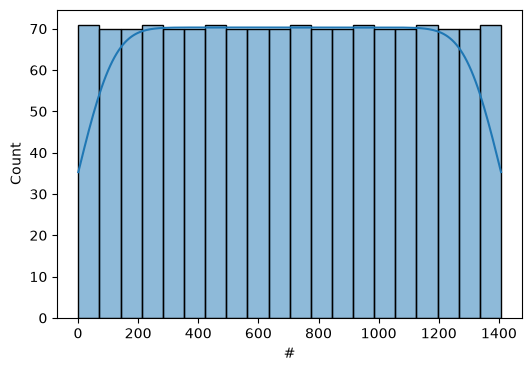

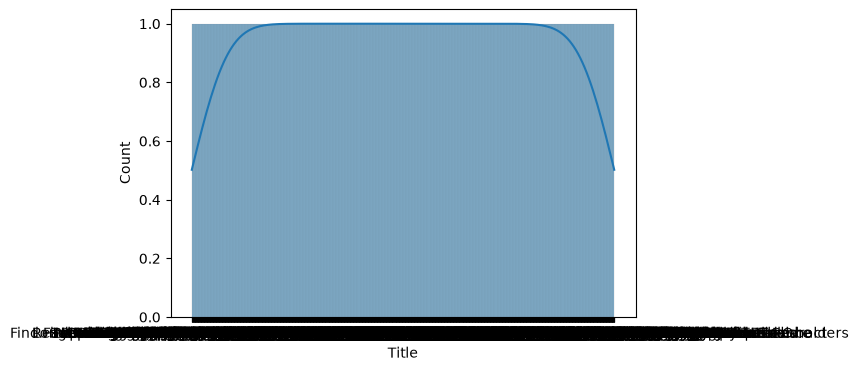

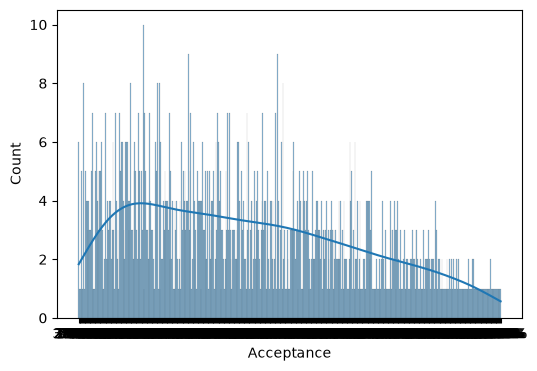

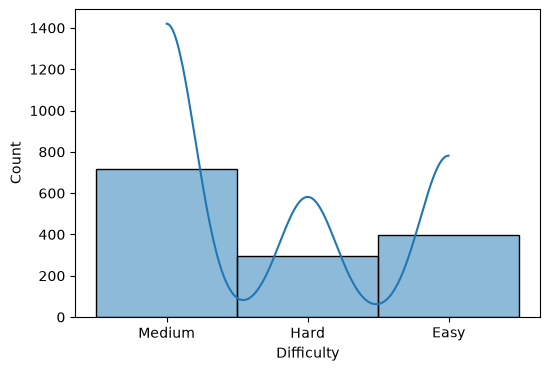

In [66]:
numeric_columns = ['#', 'Title', 'Acceptance', 'Difficulty']
for col in numeric_columns:
    plt.figure(figsize = (6,4))
    sns.histplot(df[col],kde = True , bins = 20)

<Axes: xlabel='Difficulty', ylabel='count'>

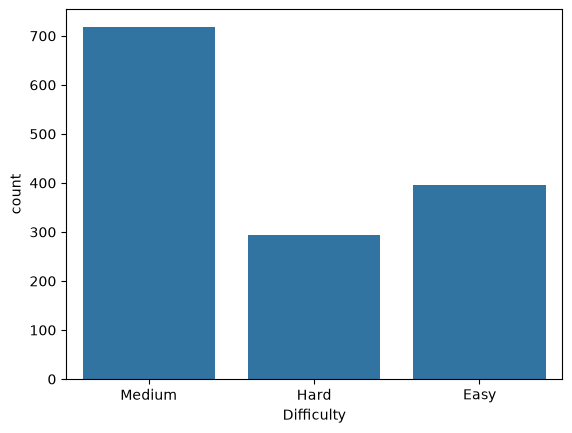

In [67]:
sns.countplot(x = df['Difficulty'])

<Axes: ylabel='count'>

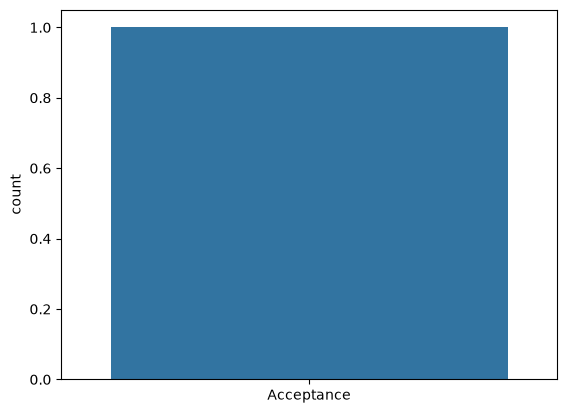

In [68]:
sns.countplot(x = ['Acceptance'])

In [69]:
df.rename(columns={
    '#' :'number',
                          },inplace = True)

In [70]:
df.head()

,number,Title,Acceptance,Difficulty
0,2,Add Two Numbers,33.00%,Medium
1,4,Median of Two Sorted Arrays,28.70%,Hard
2,5,Longest Palindromic Substring,28.90%,Medium
3,6,ZigZag Conversion,35.10%,Medium
4,8,String to Integer (atoi),15.10%,Medium


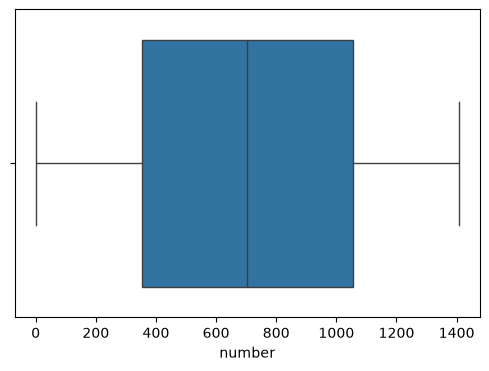

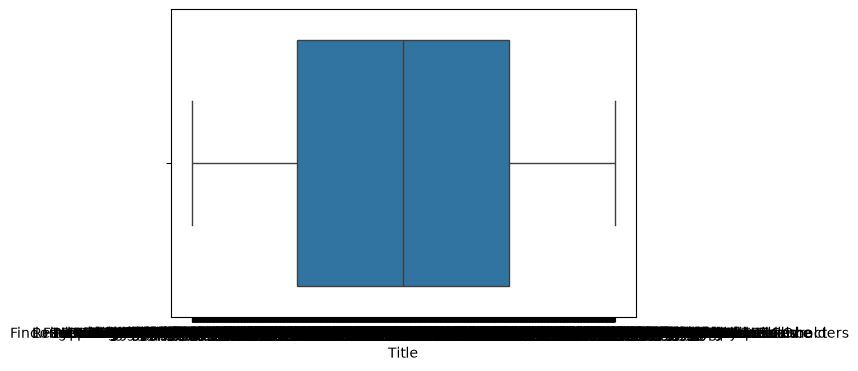

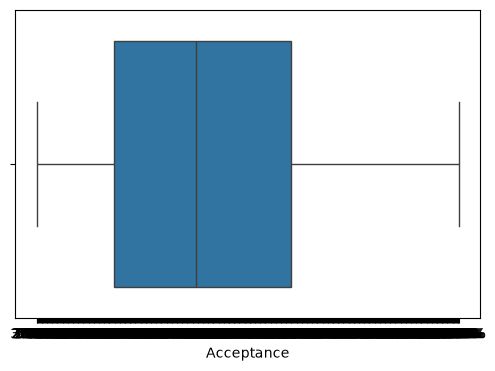

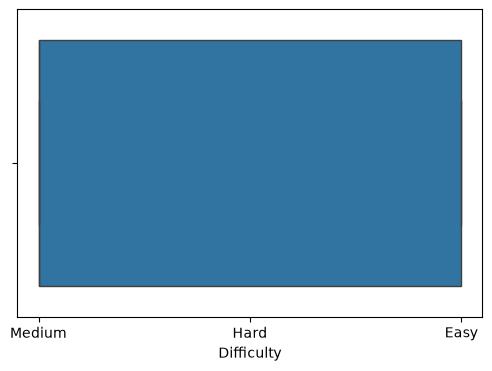

In [71]:
numeric_columns1 = ['number', 'Title', 'Acceptance', 'Difficulty']
for col in numeric_columns1:
    plt.figure(figsize= (6,4))
    sns.boxplot(x = df[col])

<Axes: >

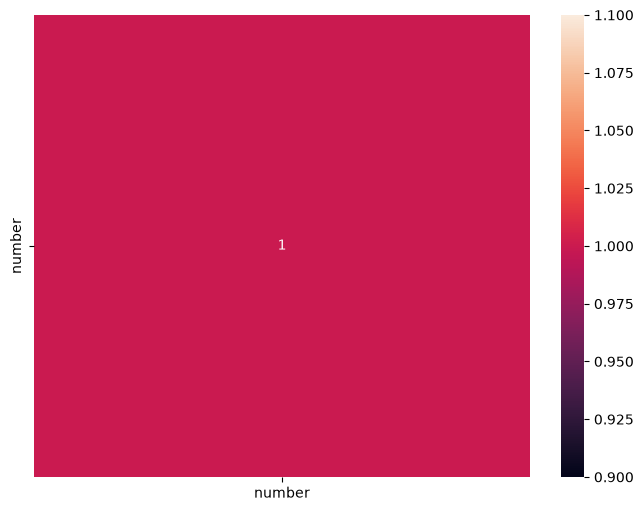

In [72]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot = True)

In [73]:
df_cleaned = df.copy()

In [74]:
df_cleaned.head()

,number,Title,Acceptance,Difficulty
0,2,Add Two Numbers,33.00%,Medium
1,4,Median of Two Sorted Arrays,28.70%,Hard
2,5,Longest Palindromic Substring,28.90%,Medium
3,6,ZigZag Conversion,35.10%,Medium
4,8,String to Integer (atoi),15.10%,Medium


In [75]:
df_cleaned.drop_duplicates(inplace = True)

In [76]:
df_cleaned.shape

(1407, 4)

In [77]:
df_cleaned.isnull().sum()

number        0
Title         0
Acceptance    0
Difficulty    0
dtype: int64

In [78]:
df_cleaned['Difficulty'].value_counts()

Difficulty
Medium    718
Easy      395
Hard      294
Name: count, dtype: int64

In [79]:
df_cleaned.head()

,number,Title,Acceptance,Difficulty
0,2,Add Two Numbers,33.00%,Medium
1,4,Median of Two Sorted Arrays,28.70%,Hard
2,5,Longest Palindromic Substring,28.90%,Medium
3,6,ZigZag Conversion,35.10%,Medium
4,8,String to Integer (atoi),15.10%,Medium


In [81]:
df_cleaned = pd.get_dummies(df_cleaned,columns = ['Difficulty'],drop_first=True)

In [83]:
df_cleaned.head()

,number,Title,Acceptance,Difficulty_Hard,Difficulty_Medium
0,2,Add Two Numbers,33.00%,False,True
1,4,Median of Two Sorted Arrays,28.70%,True,False
2,5,Longest Palindromic Substring,28.90%,False,True
3,6,ZigZag Conversion,35.10%,False,True
4,8,String to Integer (atoi),15.10%,False,True


In [86]:

bool_cols = ['Difficulty_Hard', 'Difficulty_Medium']
df_cleaned[bool_cols] = df_cleaned[bool_cols].astype(int)

df_cleaned['Acceptance'] = (
    df_cleaned['Acceptance']
    .str.rstrip('%')
    .astype(float)
    .astype(int)
)

df_cleaned.head()

,number,Title,Acceptance,Difficulty_Hard,Difficulty_Medium
0,2,Add Two Numbers,33,0,1
1,4,Median of Two Sorted Arrays,28,1,0
2,5,Longest Palindromic Substring,28,0,1
3,6,ZigZag Conversion,35,0,1
4,8,String to Integer (atoi),15,0,1


In [88]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

In [89]:
X , y_true = make_blobs(n_samples=500, centers=3, cluster_std=0.60, random_state=42)
scaler = StandardScaler()

In [90]:
X

array([[-6.1900632 , -7.30201545],
       [ 3.02174685,  1.94059276],
       [ 5.9537606 ,  1.48819071],
       [-2.74446251,  8.13617716],
       [ 5.36060719,  1.72832446],
       [ 5.13808033,  1.45951939],
       [-5.34357647, -6.93774553],
       [ 4.80215293,  1.94302682],
       [ 3.99930658,  1.88774199],
       [-7.25451834, -6.86445496],
       [ 4.25193511,  1.32424088],
       [-1.81404028,  8.52187674],
       [-1.2293776 ,  7.84303345],
       [-2.16666332,  9.69562551],
       [ 4.81374375,  3.21841016],
       [ 5.27493353,  0.91792599],
       [-2.5524037 ,  9.61640587],
       [-7.5532604 , -6.65066375],
       [-6.8302568 , -6.24082137],
       [-3.17299861,  8.29656215],
       [ 3.80073829,  2.31095123],
       [-2.38387947,  7.83848405],
       [ 4.98581301,  2.15991978],
       [-5.94031277, -6.91955975],
       [-7.14748736, -6.7636556 ],
       [ 4.87655012,  1.720579  ],
       [ 4.48689251,  2.87556548],
       [-6.4081471 , -6.62483506],
       [-6.71939703,

In [91]:
df = pd.DataFrame(X , columns=['Feature 1' , 'Feature 2'])

In [92]:
df

,Feature 1,Feature 2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [ ]:
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

def recommend_questions(user_input, df, feature_cols, solved_list=None, top_n=5):
    if solved_list is None:
        solved_list = []
        
    idx = None
    
    # 1. Check if the user entered a Serial Number (integer)
    try:
        sr_no = int(user_input)
        if sr_no in df.index:
            idx = sr_no
    except ValueError:
        # 2. If it's not a number, treat it as a Question Title (case-insensitive search)
        match = df[df['Title'].str.lower() == str(user_input).strip().lower()]
        if not match.empty:
            idx = match.index[0]
            
    # If no match found by either method
    if idx is None:
        return f"❌ Error: Could not find a question matching '{user_input}'. Check your Sr. No. or Title."
        
    selected_title = df.loc[idx, 'Title']
    print(f"\n🔍 Selected Question: [Sr. No. {idx}] {selected_title}\n" + "-"*40)
    
    # 3. Compute Cosine Similarity
    feature_matrix = df[feature_cols].values
    similarities = cosine_similarity(feature_matrix[idx].reshape(1, -1), feature_matrix).flatten()
    
    # Sort indices by highest similarity score
    sorted_indices = similarities.argsort()[::-1]
    
    recommendations = []
    
    # 4. Pick top_n items (skipping the selected question and solved ones)
    for i in sorted_indices:
        title = df.iloc[i]['Title']
        
        if i == idx or title in solved_list:
            continue
            
        recommendations.append({"Sr. No.": i, "Title": title})
        
        if len(recommendations) == top_n:
            break
            
    return recommendations

# --- EXAMPLE USAGE IN A BACKEND LOOP ---

# Define your features (everything except the Title column)
features = [col for col in df_cleaned.columns if col != 'Title']
solved_questions = ["Valid Parentheses"] # Example of tracked solved items

# Simulate user input (User can type a number like `0` or a name like `"Two Sum"`)
user_query = input("Enter Question Sr. No. or Name: ")

# Get recommendations
results = recommend_questions(
    user_input=user_query, 
    df=df_cleaned, 
    feature_cols=features, 
    solved_list=solved_questions, 
    top_n=5
)

# Display results
if isinstance(results, str):
    print(results)
else:
    print("Recommended Similar Questions:")
    for rec in results:
        print(f"• [Sr. No. {rec['Sr. No.']}] {rec['Title']}")